# Simple version: EDA + ML + a model-selector agent (Walmart weekly sales)

One notebook, three short parts, built to be **easy to explain in a viva**.

| Part | What it does | Lines |
|---|---|---|
| 1. EDA | 6 checks: data quality, skew, seasonality, holidays, stores, drivers | about 60 |
| 2. ML | 4 models + rolling-origin test + significance test | about 90 |
| 3. Agent | profiles the data, **shortlists** models, runs a tournament, **picks the winner by evidence** | about 40 |

It saves the same files as your long ML notebook (`ml_outputs/cv_predictions.csv`, `forecast_next_12_weeks.csv`, `leaderboard_validation.csv`),
so the agent notebook (`Walmart_Agentic_Simple`) works unchanged. **Change `OUT` below if you do not want to overwrite your earlier outputs.**
Needs `Walmart.csv` in the same folder.

In [28]:
%pip install -q lightgbm statsmodels scipy

Note: you may need to restart the kernel to use updated packages.


In [30]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from lightgbm import LGBMRegressor
try: display
except NameError: display = print          # lets the same code run outside Jupyter

OUT = Path("ml_outputs"); OUT.mkdir(exist_ok=True)
H = 12                                   # forecast horizon in weeks
ORIGINS = [95, 107, 119, 131]            # 4 rolling folds: train on weeks before the origin, test on the next 12

df = pd.read_csv(r"C:\Users\kumar\Desktop\Study\VIT\Mona - VIT\Semester 4\Project\walmart-sales-dataset-of-45stores.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

# Part 1: EDA (6 questions the data must answer)

In [31]:
# Q1 Is the data clean?
print("rows, columns:", df.shape, "| stores:", df.Store.nunique(), "| weeks:", df.Date.nunique())
print("missing values:", int(df.isna().sum().sum()), "| duplicate store-weeks:", int(df.duplicated(["Store", "Date"]).sum()),
      "| week gaps (days):", df.groupby("Store")["Date"].diff().dt.days.dropna().unique())
print("sales <= 0:", int((df.Weekly_Sales <= 0).sum()), "| holiday weeks flagged:", df.loc[df.Holiday_Flag == 1, "Date"].nunique())
display(df.describe().T.round(2))

rows, columns: (6435, 8) | stores: 45 | weeks: 143
missing values: 0 | duplicate store-weeks: 0 | week gaps (days): [7.]
sales <= 0: 0 | holiday weeks flagged: 10


,count,mean,min,25%,50%,75%,max,std
Store,6435.0,23.0,1.0,12.0,23.0,34.0,45.0,12.988182
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,6435.0,1046964.877562,209986.25,553350.105,960746.04,1420158.66,3818686.45,564366.622054
Holiday_Flag,6435.0,0.06993,0.0,0.0,0.0,0.0,1.0,0.255049
Temperature,6435.0,60.663782,-2.06,47.46,62.67,74.94,100.14,18.444933
Fuel_Price,6435.0,3.358607,2.472,2.933,3.445,3.735,4.468,0.45902
CPI,6435.0,171.578394,126.064,131.735,182.616521,212.743293,227.232807,39.356712
Unemployment,6435.0,7.999151,3.879,6.891,7.874,8.622,14.313,1.875885


skew of sales: 0.67 | skew of log sales: -0.31


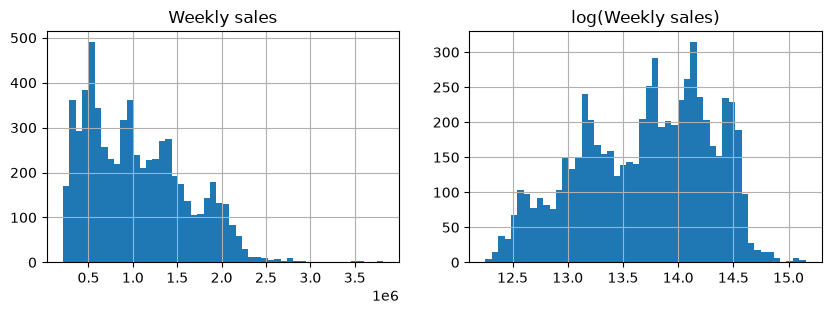

In [32]:
# Q2 What does the target look like? (skew -> we model log sales / ratios, not raw sales)
print("skew of sales:", round(df.Weekly_Sales.skew(), 2), "| skew of log sales:", round(np.log(df.Weekly_Sales).skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3)); df.Weekly_Sales.hist(bins=50, ax=ax[0]); np.log(df.Weekly_Sales).hist(bins=50, ax=ax[1])
ax[0].set_title("Weekly sales"); ax[1].set_title("log(Weekly sales)"); plt.show()

seasonal strength (0 to 1): 0.99 | autocorrelation at lag 52: 0.93


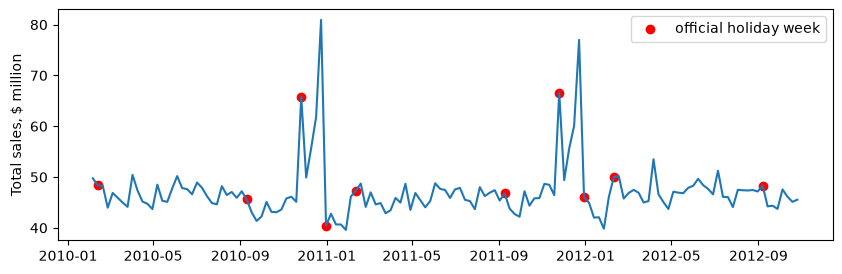

In [33]:
# Q3 Is there seasonality? (total sales per week, STL decomposition, autocorrelation at lag 52)
total = df.groupby("Date")["Weekly_Sales"].sum()
stl = STL(np.log(total), period=52).fit()
season_strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print("seasonal strength (0 to 1):", round(season_strength, 2), "| autocorrelation at lag 52:", round(total.autocorr(52), 2))
flag = df.groupby("Date")["Holiday_Flag"].max()
plt.figure(figsize=(10, 3)); plt.plot(total / 1e6); plt.scatter(flag[flag == 1].index, total[flag == 1] / 1e6, color="red", label="official holiday week")
plt.ylabel("Total sales, $ million"); plt.legend(); plt.show()

In [34]:
# Q4 Are holidays really different? Sales of each week relative to the store's own average
df["rel"] = df.Weekly_Sales / df.groupby("Store")["Weekly_Sales"].transform("mean")
def event(r):
    m, d = r.Date.month, r.Date.day
    if r.Holiday_Flag == 1: return {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas (flag week)"}[m]
    return "Pre-Christmas (not flagged)" if (m == 12 and 20 <= d <= 26) else "Normal"
df["event"] = df.apply(event, axis=1)
display(df.groupby("event")["rel"].agg(["mean", "count"]).round(2).sort_values("mean", ascending=False))   # >1 means above store average

,mean,count
event,,
Pre-Christmas (not flagged),1.61,90
Thanksgiving,1.38,90
Super Bowl,1.03,135
Labor Day,1.00,135
Normal,0.99,5895
Christmas (flag week),0.92,90


largest store / smallest store: 8.1 x


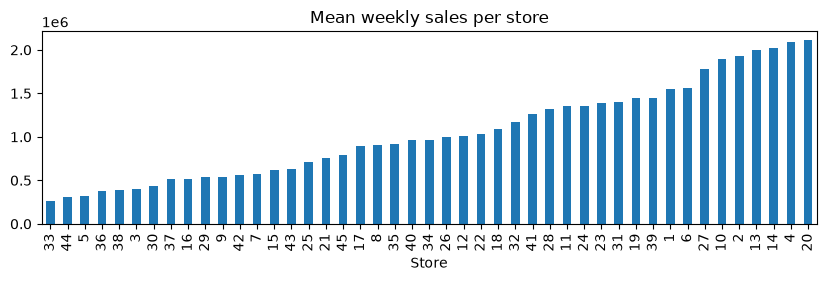

In [35]:
# Q5 Do stores differ? (size spread, and are stores' seasonal shapes similar?)
mean_sales = df.groupby("Store")["Weekly_Sales"].mean()
print("largest store / smallest store:", round(mean_sales.max() / mean_sales.min(), 1), "x")
df.groupby("Store")["Weekly_Sales"].mean().sort_values().plot.bar(figsize=(10, 2.5), title="Mean weekly sales per store"); plt.show()

In [36]:
# Q6 Do temperature, fuel price, CPI, unemployment matter? (compare stores with themselves: subtract each store's average)
cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
within = df[cols] - df.groupby("Store")[cols].transform("mean")
print("within-store Spearman correlation with sales:"); display(within.corr(method="spearman")["Weekly_Sales"].drop("Weekly_Sales").round(3))
print("""EDA findings -> modelling decisions
 1. clean data, no gaps                          -> no cleaning needed
 2. sales are right-skewed                       -> predict a ratio / log, not raw sales
 3. strong yearly seasonality (lag 52)           -> use sales from last year as a feature, test Seasonal Naive and ETS
 4. pre-Christmas week is not flagged            -> add our own event columns, do not rely on Holiday_Flag
 5. stores differ a lot in size                  -> use store-relative features
 6. weather/macro correlations are small         -> not used as features (and they are unknown 12 weeks ahead)""")

within-store Spearman correlation with sales:


Temperature     0.027
Fuel_Price      0.015
CPI             0.079
Unemployment   -0.119
Name: Weekly_Sales, dtype: float64

EDA findings -> modelling decisions
 1. clean data, no gaps                          -> no cleaning needed
 2. sales are right-skewed                       -> predict a ratio / log, not raw sales
 3. strong yearly seasonality (lag 52)           -> use sales from last year as a feature, test Seasonal Naive and ETS
 4. pre-Christmas week is not flagged            -> add our own event columns, do not rely on Holiday_Flag
 5. stores differ a lot in size                  -> use store-relative features
 6. weather/macro correlations are small         -> not used as features (and they are unknown 12 weeks ahead)


# Part 2: ML (small, but with the checks that matter)
**Three ideas to explain in the viva**
1. **No cheating (leakage):** to forecast week *t* we only use sales from weeks *t-12 or older*, because the forecast is 12 weeks ahead. A short test below proves it.
2. **Rolling origin:** 4 times, train on the past and test on the next 12 weeks, then average. Folds 1-3 pick the model, fold 4 is a final check.
3. **Target = ratio to last year:** the model predicts `log(sales / sales 52 weeks ago)`. This removes store size and gives much better results than raw sales.

In [37]:
# Build one table with history + the 12 future weeks to be forecast
dates = sorted(df.Date.unique())
flag_by_date = df.groupby("Date")["Holiday_Flag"].max()
fut_dates = pd.date_range(dates[-1] + pd.Timedelta(days=7), periods=H, freq="7D")
fut = pd.DataFrame([(s, d) for s in df.Store.unique() for d in fut_dates], columns=["Store", "Date"])
fut["Holiday_Flag"] = [int(flag_by_date.get(d - pd.Timedelta(days=364), 0)) for d in fut.Date]     # holiday = same week last year
full = pd.concat([df[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]], fut]).sort_values(["Store", "Date"]).reset_index(drop=True)

def build_features(t):
    f = t.copy(); g = f.groupby("Store")["Weekly_Sales"]
    f["lag12"], f["lag26"], f["lag52"] = g.shift(12), g.shift(26), g.shift(52)              # sales 12, 26, 52 weeks earlier
    f["roll13"] = g.transform(lambda s: s.shift(12).rolling(13).mean())                       # average of 13 weeks, ending 12 weeks ago
    f["f12"], f["f26"], f["froll"] = np.log(f.lag12 / f.lag52), np.log(f.lag26 / f.lag52), np.log(f.roll13 / f.lag52)
    f["week"], f["month"] = f.Date.dt.isocalendar().week.astype(int), f.Date.dt.month
    f["sin52"], f["cos52"] = np.sin(2 * np.pi * f.week / 52), np.cos(2 * np.pi * f.week / 52)
    fl = f.Holiday_Flag == 1
    f["ev_superbowl"], f["ev_laborday"], f["ev_thanks"], f["ev_xmas"] = [(fl & (f.month == m)).astype(int) for m in (2, 9, 11, 12)]
    f["ev_preXmas"] = ((f.month == 12) & f.Date.dt.day.between(20, 26) & ~fl).astype(int)  # the week the official flag misses
    return f
FEATS = ["week", "month", "sin52", "cos52", "Holiday_Flag", "ev_superbowl", "ev_laborday", "ev_thanks", "ev_xmas", "ev_preXmas", "f12", "f26", "froll"]
feat = build_features(full)

# Leakage test: hide all sales after fold 1's origin, rebuild features, they must be identical for the forecast weeks
O = ORIGINS[0]; hidden = full.copy(); hidden.loc[hidden.Date >= dates[O], "Weekly_Sales"] = np.nan
a = feat[feat.Date.isin(dates[O:O + H])][FEATS + ["lag52"]]
b = build_features(hidden).loc[a.index, FEATS + ["lag52"]]
assert np.allclose(a.fillna(-1).values, b.fillna(-1).values), "LEAK: features use future sales!"
print("Leakage test passed: forecast-week features do not use any future sales.")

Leakage test passed: forecast-week features do not use any future sales.


In [46]:
def seasonal_naive(train, test): return test["lag52"].values                                   # same week last year

def ets(train, test):                                                                           # one ETS model per store, on log sales
    pred = pd.Series(np.nan, index=test.index)
    for s, tr in train.groupby("Store"):
        idx = test.index[test.Store == s]
        if len(tr) >= 104:                                                                      # ETS needs 2 full years of weekly history
            fit = ExponentialSmoothing(np.log(tr.Weekly_Sales.values), trend="add", damped_trend=True, seasonal="add", seasonal_periods=52).fit()
            pred[idx] = np.exp(fit.forecast(len(idx)))
        else: pred[idx] = test.loc[idx, "lag52"].values                                         # too short: fall back to Seasonal Naive
    return pred.values

def lightgbm(train, test):                                                    # one pooled model for all stores
    tr = train.dropna(subset=FEATS + ["lag52"])                               # keep rows where every feature exists
    assert len(tr) > 100, f"training table too small: {len(tr)} rows"        # an empty table would crash LightGBM
    X  = np.ascontiguousarray(tr[FEATS].to_numpy(dtype="float64"))            # plain NumPy instead of a pandas table
    y  = np.ascontiguousarray(np.log(tr.Weekly_Sales / tr.lag52).to_numpy(dtype="float64"))   # target as plain NumPy
    w  = np.where(tr.Holiday_Flag == 1, 5.0, 1.0)                             # holiday weeks count 5x
    m = LGBMRegressor(objective="mae", n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, random_state=42, verbose=-1, n_jobs=1)   # n_jobs=1 avoids Windows threading problems
    m.fit(X, y, sample_weight=w)                                              # train
    Xt = np.ascontiguousarray(test[FEATS].to_numpy(dtype="float64"))          # test features as NumPy
    return test["lag52"].to_numpy(dtype="float64") * np.exp(m.predict(Xt))    # turn the predicted ratio back into dollars

BASE = {"SeasonalNaive": seasonal_naive, "ETS": ets, "LightGBM": lightgbm}

def backtest(names):
    """Rolling-origin test of the chosen models. Returns one row per store-week-model."""
    rows = []
    for k, O in enumerate(ORIGINS, 1):
        train = feat[(feat.Date < dates[O]) & feat.Weekly_Sales.notna()]
        test = feat[feat.Date.isin(dates[O:O + H])]
        P = {n: BASE[n](train, test) for n in names if n in BASE}
        if "Hybrid" in names: P["Hybrid"] = 0.5 * P["ETS"] + 0.5 * P["LightGBM"]                # average of the two
        for n, p in P.items():
            rows.append(test[["Store", "Date", "Holiday_Flag"]].assign(step=test.groupby("Store").cumcount() + 1, y=test.Weekly_Sales.values, model=n, yhat=p, fold=k))
    r = pd.concat(rows); r["err"] = r.y - r.yhat; r["abs_err"] = r.err.abs(); return r

def scores(cv):                                                                                 # WMAE counts holiday weeks 5x (Kaggle metric); average of the folds
    def one(g):
        w = np.where(g.Holiday_Flag == 1, 5, 1)
        return pd.Series({"WMAE": (w * g.abs_err).sum() / w.sum(), "MAE": g.abs_err.mean(), "RMSE": np.sqrt((g.err ** 2).mean())})
    return cv.groupby(["model", "fold"]).apply(one).groupby("model").mean()

# Part 3: the model-selector agent
**Idea:** instead of *me* deciding which models to try, an agent does what a data scientist does:
1. **Profile** the dataset (size, history length, seasonality).
2. **Shortlist** suitable models. Rules decide by default; with `GEMINI_API_KEY` an LLM may propose the list, but **code only accepts names from the allowed menu**.
3. **Tournament:** run the rolling-origin test on the shortlist (this is the evidence).
4. **Choose** the model with the lowest validation WMAE (folds 1-3) and write down why.

The LLM never picks the winner. **Evidence picks the winner; the LLM can only suggest candidates and explain.**

In [47]:
import lightgbm, pandas, numpy, sys

In [48]:
import sys, lightgbm, pandas, numpy
print(sys.version)
print("lightgbm", lightgbm.__version__, "| pandas", pandas.__version__, "| numpy", numpy.__version__)

O = ORIGINS[0]                                                    # first fold
tr = feat[(feat.Date < dates[O]) & feat.Weekly_Sales.notna()].dropna(subset=FEATS + ["lag52"])   # same filter the model uses
print("training rows in fold 1:", len(tr))                        # should be about 4,000, not 0
print("NaN in features:", tr[FEATS].isna().sum().sum(), "| inf:", np.isinf(tr[FEATS].to_numpy(dtype="float64")).sum())

3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]
lightgbm 4.7.0 | pandas 3.0.6 | numpy 2.5.3
training rows in fold 1: 1935
NaN in features: 0 | inf: 0


In [20]:
%pip install -U --force-reinstall lightgbm

  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   -------------------- ------------------- 6.6/12.6 MB 33.9 MB/s eta 0:00:01
   -------------------------------------- - 12.1/12.6 MB 29.6 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 24.3 MB/s  0:00:00
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)

  Attempting uninstall: numpy

    Found existing installation: numpy 2.5.3

   ---------------------------------------- 0/4 [numpy]
   ---------------------------------------- 0/4 [numpy]
   ---------------------------------------- 0/4 [numpy]
   ---------------------------------------- 0/4 [numpy]
    Uninstalling numpy-2.5.3:
   ---------------------------------------- 0/4 [numpy]
   ---------------------------------------- 0/

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


In [44]:
def lightgbm(train, test):                                                    # one pooled model for all stores
    tr = train.dropna(subset=FEATS + ["lag52"])                               # keep rows where every feature exists
    assert len(tr) > 100, f"training table too small: {len(tr)} rows"        # an empty table would crash LightGBM
    X  = np.ascontiguousarray(tr[FEATS].to_numpy(dtype="float64"))            # plain NumPy instead of a pandas table
    y  = np.ascontiguousarray(np.log(tr.Weekly_Sales / tr.lag52).to_numpy(dtype="float64"))   # target as plain NumPy
    w  = np.where(tr.Holiday_Flag == 1, 5.0, 1.0)                             # holiday weeks count 5x
    m = LGBMRegressor(objective="mae", n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, random_state=42, verbose=-1, n_jobs=1)   # n_jobs=1 avoids Windows threading problems
    m.fit(X, y, sample_weight=w)                                              # train
    Xt = np.ascontiguousarray(test[FEATS].to_numpy(dtype="float64"))          # test features as NumPy
    return test["lag52"].to_numpy(dtype="float64") * np.exp(m.predict(Xt))    # turn the predicted ratio back into dollars

In [49]:
MENU = {"SeasonalNaive": "same week last year (baseline)", "ETS": "per-store exponential smoothing, needs 2+ years",
        "LightGBM": "one pooled gradient-boosting model, needs many stores", "Hybrid": "average of ETS and LightGBM"}

def profile(d):
    wk = d.groupby("Date")["Weekly_Sales"].sum(); s = np.log(wk)
    st = STL(s, period=52).fit() if len(wk) >= 104 else None
    return {"n_stores": d.Store.nunique(), "n_weeks": len(wk),
            "seasonal_strength": round(float(max(0, 1 - st.resid.var() / (st.seasonal + st.resid).var())), 2) if st is not None else None}

def shortlist_rules(p):
    keep = ["SeasonalNaive"]                                                                   # the baseline is always in
    if p["n_weeks"] >= 104: keep.append("ETS")
    if p["n_stores"] >= 10 and p["n_weeks"] >= 60: keep.append("LightGBM")
    if "ETS" in keep and "LightGBM" in keep: keep.append("Hybrid")
    return keep

def shortlist_agent(p):
    import os, json, re
    if os.environ.get("GEMINI_API_KEY"):                                                       # optional LLM proposal, validated by code
        try:
            from google import genai
            r = genai.Client(api_key=os.environ["GEMINI_API_KEY"]).models.generate_content(model="gemini-2.5-flash",
                contents=f"Dataset profile: {p}. Menu: {MENU}. Return only a JSON list of model names worth testing.")
            names = [n for n in json.loads(re.search(r"\[.*\]", r.text, re.S).group()) if n in MENU]
            if names: return sorted(set(names) | {"SeasonalNaive"}, key=list(MENU).index), "LLM (validated against menu)"
        except Exception as e: print("LLM failed, using rules:", type(e).__name__)
    return shortlist_rules(p), "rules"

p = profile(df); names, by = shortlist_agent(p)
print("1 profile  :", p); print("2 shortlist:", names, "| chosen by", by)

# What would the agent do with a SMALLER dataset? (shows the decision really depends on the data)
p_small = profile(df[df.Date < dates[80]]); print("   same agent on only 80 weeks ->", p_small, "->", shortlist_rules(p_small))

cv = backtest(names)                                                                           # 3 tournament
val = scores(cv[cv.fold <= 3]).sort_values("WMAE"); hold = scores(cv[cv.fold == 4]).sort_values("WMAE")
winner = val.index[0]
print("4 validation leaderboard (folds 1-3, lower is better):"); display(val.round(0))
print(f"DECISION: choose {winner}. Reason: lowest validation WMAE ({val.loc[winner, 'WMAE']:,.0f}), "
      f"{100 * (1 - val.loc[winner, 'WMAE'] / val.loc['ETS', 'WMAE']):.1f}% lower than ETS ({val.loc['ETS', 'WMAE']:,.0f}). Final hold-out (fold 4): {hold.loc[winner, 'WMAE']:,.0f} vs ETS {hold.loc['ETS', 'WMAE']:,.0f}.")

1 profile  : {'n_stores': 45, 'n_weeks': 143, 'seasonal_strength': 0.99}
2 shortlist: ['SeasonalNaive', 'ETS', 'LightGBM', 'Hybrid'] | chosen by rules
   same agent on only 80 weeks -> {'n_stores': 45, 'n_weeks': 80, 'seasonal_strength': None} -> ['SeasonalNaive', 'LightGBM']


OSError: exception: access violation reading 0x0000000000000000

## Is the winner really better, or just lucky? (Diebold-Mariano test + store count)

In [50]:
def dm_test(a, b, h=H):
    """Harvey-Leybourne-Newbold version of the Diebold-Mariano test on average |error| per week. Small p => real difference."""
    w = cv[cv.model.isin([a, b])].pivot_table(index=["Store", "Date"], columns="model", values="abs_err")
    d = (w[a] - w[b]).groupby("Date").mean().sort_index().values; n = len(d); dc = d - d.mean()
    var = (np.sum(dc ** 2) + 2 * sum(np.sum(dc[k:] * dc[:n - k]) for k in range(1, h))) / n ** 2
    stat = d.mean() / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    per_store = w.groupby("Store").mean()
    return {"gain_%": round(float(100 * (1 - w[a].mean() / w[b].mean())), 1), "DM_p": round(float(2 * (1 - stats.t.cdf(abs(stat), n - 1))), 3),
            "stores_better_%": int(round(100 * (per_store[a] < per_store[b]).mean()))}
if winner != "ETS": print(f"{winner} vs ETS:", dm_test(winner, "ETS"))
print("ETS vs SeasonalNaive:", dm_test("ETS", "SeasonalNaive"))

NameError: name 'winner' is not defined

## Final forecast for the next 12 weeks + save the files used by the agent notebook

In [14]:
train_all = feat[feat.Weekly_Sales.notna()]; future = feat[feat.Date.isin(fut_dates)]
fp = {n: BASE[n](train_all, future) for n in BASE if n in names}
if winner == "Hybrid": fp["Hybrid"] = 0.5 * fp["ETS"] + 0.5 * fp["LightGBM"]
ratio = (cv[(cv.model == winner) & (cv.fold <= 3)].eval("y / yhat"))                          # how far reality was from the forecast in the backtest
q10, q90 = ratio.quantile(0.10), ratio.quantile(0.90)                                           # -> 80% range
out = future[["Store", "Date"]].assign(step=future.groupby("Store").cumcount() + 1, forecast=fp[winner])
out["lo80"], out["hi80"] = out.forecast * q10, out.forecast * q90

cv.to_csv(OUT / "cv_predictions.csv", index=False); out.to_csv(OUT / "forecast_next_12_weeks.csv", index=False)
val.reset_index().to_csv(OUT / "leaderboard_validation.csv", index=False); hold.reset_index().to_csv(OUT / "holdout_fold4.csv", index=False)
print(f"Saved 4 files to {OUT}/ | chain forecast for next {H} weeks: ${out.forecast.sum() / 1e6:,.1f}M "
      f"(80% range ${out.lo80.sum() / 1e6:,.1f}M to ${out.hi80.sum() / 1e6:,.1f}M)")
out.groupby("Date")["forecast"].sum().div(1e6).plot(figsize=(9, 3), marker="o", title="Chain forecast, $ million per week"); plt.show()

OSError: exception: access violation reading 0x0000000000000000

In [ ]:
# %% [markdown]
# # Three small agents that add measurable value: Feature Discovery, Forecast QA Guard, Planner test
#
# **Project:** Agentic Forecasting Analyst. **Problem statement:** How can a multi-agent LLM system forecast weekly store sales accurately, and explain the forecast in plain language with numbers that are verifiably faithful to the data?
#
# This notebook adds three agents on top of your EDA and ML notebooks. Each one is tested against a **traditional baseline**, so you can show a *measured* benefit.
#
# | # | Agent | Question it answers | Traditional approach it is compared with | Evidence you will get |
# |---|---|---|---|---|
# | 1 | **Feature Discovery Agent** | Where does the model fail, and can a new feature fix it? | An analyst picks features by hand once | Validation error before vs after, features accepted and *rejected* |
# | 2 | **Forecast QA Guard** | Is this forecast safe to publish? | Forecast is published without checks | Share of injected faults caught, false alarms, error with and without guard |
# | 3 | **Planner test** | Does an LLM understand questions better than fixed rules? | A rule-based parser (regular expressions) | Accuracy on 20 test questions |
#
# **How the agents work (same pattern in 1 and 2):** *observe -> hypothesize -> test with code -> accept only if the evidence says so.*
# **The LLM is optional and never decides.** Code runs every test; the LLM may only suggest candidates or understand a question, and its output is validated by code.
#
# **Before running:** keep `Walmart.csv` in the same folder. No other notebook is needed. Run time is about 2 minutes. For the LLM parts, set `GEMINI_API_KEY` (free key from Google AI Studio); everything else runs without it.
 
# %%
# %pip install -q lightgbm scipy
 
# %% [markdown]
# ## 0. Setup: data, features and a small model (shared by the agents)
# **What:** load the data, build features, and define one small LightGBM model that predicts `log(sales / sales 52 weeks ago)` for the next 12 weeks.
# **Why:** all three agents need the same simple, honest forecasting engine and the same test (rolling origin: train on the past, test on the next 12 weeks, 4 times).
# **Key idea to explain:** every feature that looks at the past is at least **12 weeks old**, because the forecast is 12 weeks ahead. So the model never sees data it would not have in real life (no *leakage*).
 
# %%
import os, re, json, warnings                          # os: read the API key; re: text patterns; json: read LLM answers; warnings: hide noise
warnings.filterwarnings("ignore")                      # keep the output clean for beginners
import numpy as np, pandas as pd                       # numpy = maths, pandas = tables
from lightgbm import LGBMRegressor                     # the forecasting model (gradient boosting trees)
try: display                                           # 'display' exists inside Jupyter ...
except NameError: display = print                      # ... and falls back to print when running as a plain script
 
H = 12                                                 # forecast horizon: 12 weeks ahead
ORIGINS = [95, 107, 119, 131]                          # rolling origins: fold k trains on weeks before the origin and tests on the next 12 weeks
df = pd.read_csv("Walmart.csv")                        # read the Kaggle Walmart file
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")   # convert text dates (dd-mm-yyyy) to real dates
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)  # sort so each store's weeks are in time order
dates = sorted(df.Date.unique())                       # the 143 distinct week-ending dates
print(df.shape, "| stores:", df.Store.nunique(), "| weeks:", len(dates))   # quick sanity check of the data size
 
# %%
flag_by_date = df.groupby("Date")["Holiday_Flag"].max()                              # was this week an official holiday week? (same for all stores)
fut_dates = pd.date_range(dates[-1] + pd.Timedelta(days=7), periods=H, freq="7D")    # the 12 future weeks we must forecast
fut = pd.DataFrame([(s, d) for s in df.Store.unique() for d in fut_dates], columns=["Store", "Date"])   # one row per store per future week
fut["Holiday_Flag"] = [int(flag_by_date.get(d - pd.Timedelta(days=364), 0)) for d in fut.Date]          # future holiday = same week last year
full = pd.concat([df[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]], fut]).sort_values(["Store", "Date"]).reset_index(drop=True)  # history + future in one table
 
EASTER = {pd.Timestamp(x) for x in ["2010-04-04", "2011-04-24", "2012-04-08", "2013-03-31"]}   # Easter Sundays (public calendar facts)
CANDIDATES = {                                         # the agent's "hypothesis menu": calendar events that might change sales
    "ev_preXmas":   lambda f: (f.month == 12) & f.Date.dt.day.between(20, 26) & (f.Holiday_Flag == 0),   # week before Christmas (not flagged in the data)
    "ev_thanks":    lambda f: (f.Holiday_Flag == 1) & (f.month == 11),                                    # Thanksgiving week
    "ev_xmas":      lambda f: (f.Holiday_Flag == 1) & (f.month == 12),                                    # flagged Christmas week
    "ev_superbowl": lambda f: (f.Holiday_Flag == 1) & (f.month == 2),                                     # Super Bowl week
    "ev_laborday":  lambda f: (f.Holiday_Flag == 1) & (f.month == 9),                                     # Labor Day week
    "ev_easter":    lambda f: (f.Date + pd.Timedelta(days=2)).isin(EASTER),                               # the Friday just before Easter Sunday (never flagged)
    "ev_july4":     lambda f: (f.month == 7) & f.Date.dt.day.between(4, 10),                              # week containing 4 July
}
 
def build_features(t):
    f = t.copy()                                                          # work on a copy
    g = f.groupby("Store")["Weekly_Sales"]                                # sales per store, in time order
    f["lag12"], f["lag26"], f["lag52"] = g.shift(12), g.shift(26), g.shift(52)   # sales 12, 26 and 52 weeks earlier
    f["roll13"] = g.transform(lambda s: s.shift(12).rolling(13).mean())   # average of 13 weeks, ending 12 weeks ago
    f["f12"], f["f26"], f["froll"] = np.log(f.lag12 / f.lag52), np.log(f.lag26 / f.lag52), np.log(f.roll13 / f.lag52)   # ratios to last year (removes store size)
    f["week"], f["month"] = f.Date.dt.isocalendar().week.astype(int), f.Date.dt.month   # week of year and month
    f["sin52"], f["cos52"] = np.sin(2 * np.pi * f.week / 52), np.cos(2 * np.pi * f.week / 52)   # smooth yearly cycle
    for name, rule in CANDIDATES.items(): f[name] = rule(f).astype(int)   # add every candidate event as a 0/1 column (not used until accepted)
    return f
 
feat = build_features(full)                                               # the full feature table (history + future)
BASE = ["week", "sin52", "cos52", "month", "Holiday_Flag", "f12", "f26", "froll"]   # M0: the "first model an analyst would build"
print("Base features (M0):", BASE)                                        # show what the starting model knows
print("Candidate events the agent may test:", list(CANDIDATES))           # show the hypothesis menu
 
# %%
def run_backtest(feats, seed=42):
    """Rolling-origin test of the LightGBM model that uses the feature list `feats`."""
    rows = []                                                             # collect each fold's predictions here
    for k, O in enumerate(ORIGINS, 1):                                    # fold number k and its origin week O
        train = feat[(feat.Date < dates[O]) & feat.Weekly_Sales.notna()].dropna(subset=feats + ["lag52"])   # only weeks BEFORE the origin
        test = feat[feat.Date.isin(dates[O:O + H])]                       # the next 12 weeks (unknown to the model)
        m = LGBMRegressor(objective="mae", n_estimators=300, learning_rate=0.05, num_leaves=15,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1)   # small, fast model
        m.fit(train[feats], np.log(train.Weekly_Sales / train.lag52),
              sample_weight=np.where(train.Holiday_Flag == 1, 5, 1))      # target = ratio to last year; holiday weeks count 5x (Kaggle rule)
        yhat = test.lag52.values * np.exp(m.predict(test[feats]))         # turn the predicted ratio back into dollars
        rows.append(test[["Store", "Date", "Holiday_Flag"]].assign(y=test.Weekly_Sales.values, yhat=yhat, fold=k))   # keep actual and forecast
    cv = pd.concat(rows)                                                  # all folds in one table
    cv["err"], cv["abs_err"] = cv.y - cv.yhat, (cv.y - cv.yhat).abs()    # signed and absolute error in dollars
    return cv
 
def wmae(cv, folds=(1, 2, 3)):
    """Weighted mean absolute error (holiday weeks count 5x), averaged over the chosen folds. Lower is better."""
    out = []                                                              # one number per fold
    for k in folds:
        d = cv[cv.fold == k]                                              # rows of this fold
        w = np.where(d.Holiday_Flag == 1, 5, 1)                           # weight 5 for holiday weeks, 1 otherwise
        out.append((w * d.abs_err).sum() / w.sum())                       # weighted average absolute error
    return float(np.mean(out))                                            # average over folds
 
def call_llm(prompt, json_mode=False):
    """Ask Gemini (temperature 0 = repeatable). Returns None when there is no key, so every step has a non-LLM fallback."""
    key = os.environ.get("GEMINI_API_KEY")                                # the key lives in an environment variable, never in the notebook
    if not key: return None                                               # no key -> the caller uses its rule-based fallback
    try:
        from google import genai                                          # imported only when needed
        from google.genai import types
        cfg = types.GenerateContentConfig(temperature=0, response_mime_type="application/json" if json_mode else "text/plain")   # deterministic answers
        return genai.Client(api_key=key).models.generate_content(model="gemini-2.5-flash", contents=prompt, config=cfg).text      # the LLM answer
    except Exception as e:
        print("LLM failed, using fallback:", type(e).__name__); return None   # never crash the notebook because of the API
 
# %% [markdown]
# # Agent 1: Feature Discovery Agent
# **The idea:** a traditional pipeline uses the features its author thought of on day one. This agent *looks at its own mistakes*, guesses which calendar event explains them, and tests the guess.
#
# **Steps (the agent loop):**
# 1. **Observe:** run the starting model M0 and find the weeks where it makes the biggest percentage errors.
# 2. **Hypothesize:** for every candidate event, ask "does the model do worse on those weeks than on normal weeks?" and rank the candidates.
# 3. **Test:** add the top candidates **one at a time**; keep a feature only if validation error improves by **more than the random noise** of the model.
# 4. **Report:** a table of accepted and rejected features, plus a final check on the untouched hold-out fold.
#
# **Why the noise rule matters:** LightGBM uses randomness, so the same model gives slightly different errors with different seeds. A gain smaller than that noise could be luck, so the agent refuses it. Rejecting features is as important as accepting them.
 
# %%
# STEP 1  OBSERVE: run the starting model M0 and measure how noisy its score is
cv0 = run_backtest(BASE)                                                  # M0 backtest with the default seed
base_score = wmae(cv0)                                                    # M0 validation error (folds 1-3), the number to beat
seeds = [wmae(run_backtest(BASE, seed=s)) for s in (1, 7, 42)]            # same model, three random seeds
NOISE = (max(seeds) - min(seeds)) / np.mean(seeds)                        # relative spread caused only by randomness
MIN_GAIN = max(0.01, NOISE)                                               # accept a feature only if it beats this (at least 1%)
print(f"M0 validation WMAE: ${base_score:,.0f}")                          # starting point
print(f"Random-seed noise: {NOISE:.1%}  -> a new feature must improve the score by more than {MIN_GAIN:.1%}")   # the agent's acceptance rule
 
# %%
# STEP 1 (continued)  where does M0 fail?  percentage error by week, validation folds only
diag = cv0[cv0.fold <= 3].merge(feat[["Store", "Date"] + list(CANDIDATES)], on=["Store", "Date"])   # attach the event columns to each prediction
diag["pct_err"] = diag.abs_err / diag.y                                   # error as a share of actual sales (fair across big and small stores)
worst = diag.groupby("Date").agg(mean_pct_err=("pct_err", "mean"), **{c: (c, "max") for c in CANDIDATES}).nlargest(5, "mean_pct_err")   # 5 worst weeks
worst["matching_event"] = worst[list(CANDIDATES)].apply(lambda r: ", ".join(c for c in CANDIDATES if r[c] == 1) or "none known", axis=1)  # which candidate event falls on that week
display(worst[["mean_pct_err", "matching_event"]].round(3))               # the agent's "where does it hurt?" table
 
# %%
# STEP 2  HYPOTHESIZE: score each candidate = "how much worse is the model on these weeks than on normal weeks?"
scores = {}                                                               # candidate -> error ratio
for c in CANDIDATES:                                                      # loop over the hypothesis menu
    on, off = diag[diag[c] == 1].pct_err, diag[diag[c] == 0].pct_err      # error on event weeks vs all other weeks
    if len(on) == 0: print(f"  skip {c}: never occurs in the validation folds"); continue   # cannot be tested without such weeks
    scores[c] = on.mean() / off.mean()                                    # ratio > 1 means the model struggles on this event
ranked = [c for c, s in sorted(scores.items(), key=lambda x: -x[1]) if s > 1.2]   # keep candidates with at least 20% worse error
print("Error ratio on event weeks vs normal weeks:", {c: round(s, 2) for c, s in scores.items()})   # show every score
reply = call_llm(f"Calendar events: {list(scores)}. Error ratios: {scores}. Return a JSON list of the events most worth testing, best first.", json_mode=True)   # optional LLM suggestion
try: llm_list = [c for c in json.loads(reply) if c in CANDIDATES and c in scores] if reply else []   # code accepts only names from the menu
except Exception: llm_list = []                                           # a badly formatted LLM answer is ignored
ranked = llm_list or ranked                                               # LLM order if valid, otherwise the rule-based order
print("Candidates to test, in order:", ranked, "| ordering by", "LLM (validated)" if llm_list else "rules")   # tell the reader who decided the order
 
# %%
# STEP 3  TEST: add candidates one at a time, keep only if the gain beats the noise
used, best, log = list(BASE), base_score, []                              # currently accepted feature set and its score
for c in ranked:                                                          # try each hypothesis
    trial = wmae(run_backtest(used + [c]))                                # backtest with this feature added
    gain = 1 - trial / best                                               # relative improvement (positive = better)
    accept = gain > MIN_GAIN                                              # the decision rule
    log.append({"candidate": c, "WMAE_before": round(best), "WMAE_after": round(trial), "gain": f"{gain:+.1%}", "decision": "ACCEPT" if accept else "reject"})   # remember the decision
    if accept: used, best = used + [c], trial                             # keep the feature and raise the bar
display(pd.DataFrame(log))                                                # the agent's decision log
accepted = [c for c in used if c not in BASE]                             # features the agent added
print("Accepted features:", accepted or "none")                           # headline result
 
# %%
# STEP 4  REPORT: final model vs M0 on validation AND on the untouched hold-out fold 4
cv_final = run_backtest(used)                                             # backtest of the improved model (also used by Agent 2)
easter_wk = pd.Timestamp("2012-04-06")                                    # the Easter week inside validation fold 2
summary1 = pd.DataFrame({                                                 # one small comparison table
    "M0 (analyst's features)": [wmae(cv0), wmae(cv0, (4,)), cv0[cv0.Date == easter_wk].abs_err.mean()],
    "After agent": [wmae(cv_final), wmae(cv_final, (4,)), cv_final[cv_final.Date == easter_wk].abs_err.mean()],
}, index=["Validation WMAE (folds 1-3)", "Hold-out WMAE (fold 4)", "Mean error in Easter week 2012"]).round(0)
summary1["change"] = (100 * (summary1.iloc[:, 1] / summary1.iloc[:, 0] - 1)).round(1).astype(str) + "%"   # percent change
display(summary1)
 
# %% [markdown]
# ### How to explain Agent 1 in the review
# - **Benefit over traditional ML:** the feature list is *discovered from the model's own errors* and each addition is *tested*; the traditional pipeline keeps whatever the analyst typed on day one.
# - **What it should find:** Easter week is the worst week in validation (about 12% error) and has **no holiday flag in the data**. The agent should accept `ev_easter`. It should *reject* `ev_preXmas`, because week-of-year already captures that peak: the agent does not just add everything.
# - **Hold-out result (be upfront):** fold 4 contains no Easter, so the hold-out score stays about the same (it can move slightly up or down by chance). That is expected, not a failure: the feature fixes a week that the hold-out does not contain.
# - **Honest limits:** Easter occurs once in the validation folds (2012) and not at all in the hold-out fold, so the Easter effect is confirmed on one event (but across all 45 stores and several random seeds). Only 143 weeks of data exist. The agent proposes calendar events from a fixed menu; it cannot invent features outside the menu.
 
# %% [markdown]
# # Agent 2: Forecast QA Guard
# **The idea:** a forecast with a unit error (x10), a sign error or a blank would normally be published and trusted. The guard checks every forecast before it reaches a manager; if a check fails it **swaps in a safe value (last year's sales for that week) and logs why**.
#
# **Three checks (plain rules, no LLM):**
# 1. **Valid number?** not missing, not infinite, greater than zero.
# 2. **Plausible jump?** between half and double of the same week last year.
# 3. **Inside history?** not far above the store's historical maximum or below its minimum.
#
# **How we prove it works (fault injection):** we deliberately damage 5% of the forecasts in five ways, then measure how many the guard catches, how many clean forecasts it wrongly flags (false alarms), and how much error it removes.
 
# %%
hist_max, hist_min = df.groupby("Store").Weekly_Sales.max(), df.groupby("Store").Weekly_Sales.min()   # each store's historical highest and lowest week
 
def qa_guard(fc):
    """fc needs columns: Store, yhat (forecast), lag52 (same week last year). Returns fc plus flag, reason and a safe forecast."""
    r = fc.copy()                                                         # do not change the caller's table
    bad_value = ~np.isfinite(r.yhat) | (r.yhat <= 0)                      # check 1: missing, infinite, zero or negative
    ratio = r.yhat / r.lag52                                              # forecast compared with the same week last year
    big_jump = (ratio > 2.0) | (ratio < 0.5)                              # check 2: more than double or less than half
    out_range = (r.yhat > 1.5 * r.Store.map(hist_max)) | (r.yhat < 0.5 * r.Store.map(hist_min))   # check 3: far outside the store's history
    r["flag"] = bad_value | big_jump | out_range                          # any failed check -> flagged
    r["reason"] = np.select([bad_value, big_jump, out_range], ["invalid value", "jump vs last year", "outside history"], "ok")   # first failed check
    r["yhat_safe"] = np.where(r.flag, r.lag52, r.yhat)                    # replace flagged forecasts with last year's value
    return r
 
# %%
clean = cv_final.merge(feat[["Store", "Date", "lag52"]], on=["Store", "Date"]).reset_index(drop=True)   # forecasts of the improved model + last year's sales
rng = np.random.default_rng(0)                                            # fixed seed so the experiment is repeatable
FAULTS = {"x10 (unit error)": lambda v: v * 10, "x0.1 (unit error)": lambda v: v * 0.1,
          "negative (sign error)": lambda v: -v, "missing (blank)": lambda v: np.nan, "x1.4 (subtle)": lambda v: v * 1.4}   # five kinds of damage
bad = clean.copy(); bad["fault"] = "none"                                 # damaged copy; 'none' = untouched
idx = rng.choice(len(bad), size=int(0.05 * len(bad)), replace=False)      # pick 5% of forecasts at random
for i, j in enumerate(idx):                                               # damage them, cycling through the five fault types
    name = list(FAULTS)[i % len(FAULTS)]                                  # which fault this row gets
    bad.loc[j, "yhat"], bad.loc[j, "fault"] = FAULTS[name](bad.loc[j, "yhat"]), name   # apply the damage and remember it
guarded = qa_guard(bad)                                                   # run the guard on the damaged forecasts
 
det = guarded[guarded.fault != "none"].groupby("fault").flag.mean().mul(100).round(0)   # % of damaged rows that were caught, per fault type
false_alarm = 100 * guarded[guarded.fault == "none"].flag.mean()          # % of untouched rows wrongly flagged
print("Caught by the guard, by fault type (%):"); display(det)            # detection table
print(f"Overall caught: {100 * guarded[guarded.fault != 'none'].flag.mean():.0f}% | false alarms on clean forecasts: {false_alarm:.1f}%")   # headline detection and false-alarm rates
 
def score_rows(d, col):                                                   # WMAE for a chosen forecast column (blank forecast counts as 0 = nothing ordered)
    t = d.assign(abs_err=(d.y - d[col].fillna(0)).abs()); return wmae(t, (1, 2, 3, 4))   # reuse the same metric over all four folds
results2 = pd.DataFrame({"WMAE (all folds)": {
    "Clean forecasts, no guard": score_rows(clean, "yhat"),
    "Damaged forecasts, NO guard (traditional)": score_rows(bad, "yhat"),
    "Damaged forecasts, WITH guard (agent)": score_rows(guarded, "yhat_safe"),
    "Clean forecasts, with guard (cost of false alarms)": score_rows(guarded[guarded.fault == "none"], "yhat_safe")}}).round(0)
display(results2)                                                         # the key comparison table
 
# %% [markdown]
# ### How to explain Agent 2 in the review
# - **Benefit over traditional ML:** a traditional pipeline publishes whatever the model outputs. The guard turns silent failures into **logged, repaired** ones; the table shows how much error it removes (compare the "NO guard" and "WITH guard" rows).
# - **Why it supports your problem statement:** "verifiably faithful" starts *before* the words: if the forecast itself is corrupt, a perfectly worded explanation is still wrong.
# - **Honest limits:** the **subtle x1.4 fault is mostly not caught** (a 40% error looks plausible); the guard only stops *gross* errors. Faults were injected by us, so real-world detection rates will differ. The fallback (last year's value) is simple, not optimal.
 
# %% [markdown]
# # Agent 3 (test): does an LLM understand questions better than fixed rules?
# **The idea:** the Planner turns a manager's sentence into a plan: which stores, how many weeks, and what kind of answer (forecast, accuracy, or a what-if). The traditional way is a rule-based parser (regular expressions). An LLM can read paraphrases such as "next fortnight" or "store seven".
#
# **How we test it:** 20 questions with a known correct plan (8 plain, 12 natural paraphrases). Score = share of questions where the planner gets **stores, horizon and topic all right**.
# **Fairness note:** we wrote both the questions and the rules, so this shows how brittle simple rules are on phrasing, not a general ranking of all rule systems. For a stronger test, ask a classmate to write 10 extra questions without seeing the rules.
 
# %%
TOPICS = ["forecast", "accuracy", "what_if"]                              # the three kinds of request the system supports
TESTS = [  # (question, correct stores or None = whole chain, correct horizon in weeks, correct topic)
    ("Forecast Store 20 for the next 8 weeks", [20], 8, "forecast"),                                  # --- plain questions ---
    ("What is the 12-week forecast for the whole chain?", None, 12, "forecast"),
    ("How accurate is the forecast for Store 14?", [14], 12, "accuracy"),
    ("What if Store 4 sales come in 5% below forecast?", [4], 12, "what_if"),
    ("Forecast stores 2 and 3 for the next 4 weeks", [2, 3], 4, "forecast"),
    ("How accurate is the model for the whole chain?", None, 12, "accuracy"),
    ("What is the forecast for Store 35?", [35], 12, "forecast"),
    ("What if the whole chain is 10% above forecast over the next 6 weeks?", None, 6, "what_if"),
    ("Give me the outlook for store seven for the coming two months", [7], 8, "forecast"),            # --- paraphrased questions ---
    ("Can I trust the numbers for #14?", [14], 12, "accuracy"),
    ("How will stores 4 & 10 do over the next month?", [4, 10], 4, "forecast"),
    ("What does next quarter look like for Store 20?", [20], 12, "forecast"),
    ("Is the model any good for stores 1 through 3?", [1, 2, 3], 12, "accuracy"),
    ("Suppose Store 27 underperforms by 8 percent, how bad is it?", [27], 12, "what_if"),
    ("How reliable is our forecast across all stores?", None, 12, "accuracy"),
    ("Sales projections for the chain in the next six weeks please", None, 6, "forecast"),
    ("What happens if demand at store twelve drops by a tenth?", [12], 12, "what_if"),
    ("Expected sales for Store 5 next fortnight", [5], 2, "forecast"),
    ("How far off does the model usually get for Store 33?", [33], 12, "accuracy"),
    ("Walk me through next month's sales for stores 8, 9 and 10", [8, 9, 10], 4, "forecast"),
]
print(len(TESTS), "test questions")                                       # should print 20
 
# %%
def rule_planner(q):
    """The traditional planner: digits after the word 'store', digits before 'week', and a few keywords."""
    ql = q.lower()                                                        # ignore capital letters
    ids = [int(n) for grp in re.findall(r"store[s]?\s*((?:\d+[\s,and&]*)+)", ql) for n in re.findall(r"\d+", grp)]   # numbers written right after 'store(s)'
    stores = sorted({i for i in ids if 1 <= i <= 45}) or None             # valid store numbers, or None = whole chain
    m = re.search(r"(\d+)\s*[- ]?week", ql)                               # '8 weeks', '12-week'
    horizon = min(max(int(m.group(1)), 1), H) if m else H                # default to the full 12 weeks
    if re.search(r"what if|scenario|%", ql): topic = "what_if"            # what-if keywords
    elif re.search(r"accura|error|reliab|trust|how good", ql): topic = "accuracy"   # accuracy keywords
    else: topic = "forecast"                                              # everything else is a forecast request
    return {"stores": stores, "horizon_weeks": horizon, "topic": topic}   # the plan
 
PLANNER_PROMPT = ("You plan requests for a retail forecasting assistant (stores numbered 1-45). Return ONLY JSON with keys: "
                  "stores (list of store numbers, or null for the whole chain), horizon_weeks (integer 1-12; default 12; "
                  "a fortnight is 2, a month is 4, two months is 8, a quarter is 12), topic (one of forecast, accuracy, what_if). Question: ")
 
def llm_planner(q):
    reply = call_llm(PLANNER_PROMPT + q, json_mode=True)                  # ask the LLM
    if not reply: return None                                             # no key -> cannot run this planner
    try:
        p = json.loads(reply)                                             # read the JSON
        st = p.get("stores"); st = sorted({int(x) for x in st if 1 <= int(x) <= 45}) if st else None   # keep only valid store numbers
        return {"stores": st or None, "horizon_weeks": min(max(int(p["horizon_weeks"]), 1), H),        # keep horizon between 1 and 12
                "topic": p["topic"] if p["topic"] in TOPICS else "forecast"}                           # keep only allowed topics
    except Exception: return None                                         # unreadable answer counts as a miss
 
def evaluate(planner):
    rows = []                                                             # one result row per question
    for q, st, hz, tp in TESTS:                                           # loop over the 20 test questions
        p = planner(q)                                                    # the planner's answer
        ok = p is not None and p["stores"] == st and p["horizon_weeks"] == hz and p["topic"] == tp   # all three fields must match
        rows.append({"question": q, "easy": TESTS.index((q, st, hz, tp)) < 8, "correct": bool(ok), "got": p})   # first 8 questions are the plain ones
    return pd.DataFrame(rows)
 
res_rules, res_llm = evaluate(rule_planner), evaluate(llm_planner)        # run both planners on the same questions
def acc(r, easy=None): d = r if easy is None else r[r.easy == easy]; return f"{d.correct.sum()}/{len(d)}"   # 'correct/total' helper
if res_llm.got.notna().any():                                             # LLM column only exists if a key is set
    table3 = pd.DataFrame({"Rule-based": [acc(res_rules), acc(res_rules, True), acc(res_rules, False)],
                           "LLM": [acc(res_llm), acc(res_llm, True), acc(res_llm, False)]}, index=["All 20", "8 plain", "12 paraphrased"])
else:
    table3 = pd.DataFrame({"Rule-based": [acc(res_rules), acc(res_rules, True), acc(res_rules, False)], "LLM": ["needs GEMINI_API_KEY"] * 3},
                          index=["All 20", "8 plain", "12 paraphrased"])
display(table3)                                                           # the headline comparison
display(res_rules[~res_rules.correct][["question", "got"]])               # which questions the rules got wrong (useful for the report)
 
# %% [markdown]
# ### How to explain Agent 3 in the review
# - **Benefit over traditional ML:** rules need a new regular expression for every phrasing; an LLM reads natural language. This test turns that claim into a number.
# - **What to expect:** rules do well on plain questions and fail on word numbers ("seven"), periods ("month", "quarter", "fortnight"), "#14" and ranges ("1 through 3").
# - **Without an API key** the LLM column is blank: do **not** invent a number. Run with `GEMINI_API_KEY` and report the real score. If the LLM also fails some questions, report which; that is a valid finding.
# - **Safety design:** even when the LLM understands the question, code validates the plan (stores 1-45, horizon 1-12, allowed topics), so a bad LLM answer cannot break the system.
 
# %% [markdown]
# # Summary table for your slides and report
# One row per agent, each with a **measured** comparison against the traditional approach. Copy these numbers (from *your* run) into the Results slides.
 
# %%
catch = 100 * guarded[guarded.fault != "none"].flag.mean()                # overall % of injected faults caught
summary = pd.DataFrame([
    {"Agent": "1 Feature Discovery", "Traditional approach": "features chosen once by hand",
     "Measured result": f"accepted {accepted or 'none'}; validation WMAE ${wmae(cv0):,.0f} -> ${wmae(cv_final):,.0f} ({100 * (wmae(cv_final) / wmae(cv0) - 1):+.1f}%)"},
    {"Agent": "2 Forecast QA Guard", "Traditional approach": "publish without checks",
     "Measured result": f"caught {catch:.0f}% of injected faults, {false_alarm:.1f}% false alarms; error ${results2.iloc[1, 0]:,.0f} -> ${results2.iloc[2, 0]:,.0f}"},
    {"Agent": "3 Planner (LLM vs rules)", "Traditional approach": "regular-expression parser",
     "Measured result": f"rules {acc(res_rules)} correct; LLM " + (acc(res_llm) if res_llm.got.notna().any() else "not run (no API key)")},
])
pd.set_option("display.max_colwidth", 200); display(summary)               # show the full text of each result
summary.to_csv("agent_experiments_summary.csv", index=False)              # save for your report